In [67]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import (
    Statevector, Operator, DensityMatrix,
    SparsePauliOp, Pauli, random_unitary
)
from qiskit_aer import AerSimulator
from qiskit_aer.noise import depolarizing_error

# =================== Configuration ===================
N_QUBITS = 6
DEPTHS = range(2, 22, 2)
CIRCUITS_PER_DEPTH = 10
LAMBDA_2Q = 0.99
FOLD_FACTORS = (1, 3, 5)
PAULI_SAMPLES = 64       # None for all nonidentity Paulis
SEED = 1234
# =====================================================

assert N_QUBITS >= 4 and N_QUBITS % 2 == 0
assert all(d > 0 and d % 2 == 0 for d in DEPTHS)
assert all(f > 0 and f % 2 == 1 for f in FOLD_FACTORS)

rng = np.random.default_rng(SEED)
dim = 2**N_QUBITS
sim = AerSimulator(method="density_matrix")

noise = depolarizing_error(1 - LAMBDA_2Q, 2).to_instruction()


def mean_sem(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if not len(x):
        return np.nan, np.nan
    if len(x) == 1:
        return x[0], 0.0
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x))


def hellinger(p, q):
    return np.linalg.norm(
        np.sqrt(np.clip(p, 0, None)) -
        np.sqrt(np.clip(q, 0, None))
    ) / np.sqrt(2)


def random_brickwork(depth):
    gates = []
    for layer in range(depth):
        if layer % 2 == 0:
            pairs = [(i, i + 1)
                     for i in range(0, N_QUBITS, 2)]
        else:
            pairs = [(i, (i + 1) % N_QUBITS)
                     for i in range(1, N_QUBITS, 2)]

        for pair in pairs:
            U = random_unitary(
                4, seed=int(rng.integers(2**32))
            ).to_instruction()
            gates.append((pair, U))
    return gates


def build_circuit(gates, fold=1, noisy=False):
    qc = QuantumCircuit(N_QUBITS)
    k = (fold - 1) // 2

    for pair, U in gates:
        sequence = [U]
        for _ in range(k):
            sequence.extend([U.inverse(), U])

        for op in sequence:
            qc.append(op, list(pair))
            if noisy:
                qc.append(noise, list(pair))
    return qc


def noisy_density_matrix(gates, fold=1):
    qc = build_circuit(gates, fold=fold, noisy=True)
    qc.save_density_matrix()
    return np.asarray(
        sim.run(qc).result().data(0)["density_matrix"]
    )


def lambda_from_survival(psi, rho):
    survival = np.real(np.vdot(psi, rho @ psi))
    return (survival - 1 / dim) / (1 - 1 / dim)


def best_fit_lambda(p_ideal, p_noisy):
    """L2-optimal depolarization parameter."""
    uniform = np.ones(dim) / dim
    x = p_ideal - uniform
    y = p_noisy - uniform
    denom = x @ x

    if denom < 1e-14:
        return np.nan

    return float(np.clip((x @ y) / denom, 0, 1))

def pauli_probabilities_and_std(U):
    """
    Returns:
        p: Array of all 4^n Pauli probabilities, including zeros.
        variance: Population variance of these probabilities.
    """
    op = Operator(U)
    n = op.num_qubits

    decomp = SparsePauliOp.from_operator(
        op, atol=0, rtol=0
    )

    # Allocate space for every Pauli string
    p = np.zeros(4**n)

    for label, coeff in zip(
        decomp.paulis.to_labels(), decomp.coeffs
    ):
        # Interpret the Pauli label as a base-4 integer
        index = 0
        for char in label:
            index = 4 * index + "IXYZ".index(char)

        p[index] = abs(coeff)**2

    p /= p.sum()

    std = np.std(p)

    return p, float(std)


def sample_paulis():
    total = 4**N_QUBITS - 1
    count = total if PAULI_SAMPLES is None else min(
        PAULI_SAMPLES, total
    )

    indices = rng.choice(
        np.arange(1, total + 1), size=count, replace=False
    )

    matrices = []
    for index in indices:
        digits = []
        x = int(index)
        for _ in range(N_QUBITS):
            digits.append("IXYZ"[x % 4])
            x //= 4

        label = "".join(reversed(digits))
        matrices.append(Pauli(label).to_matrix())

    return matrices


def attenuation_std(gates, pauli_matrices):
    """
    Diagonal PTM coefficients in the ideal interaction frame,
    without constructing the full PTM or superoperator.
    """
    values = []

    for P in pauli_matrices:
        ideal = DensityMatrix(P)
        noisy = DensityMatrix(P)

        for pair, U in gates:
            ideal = ideal.evolve(U, qargs=list(pair))
            noisy = noisy.evolve(U, qargs=list(pair))
            noisy = noisy.evolve(noise, qargs=list(pair))

        attenuation = np.trace(
            ideal.data.conj().T @ noisy.data
        ).real / dim

        values.append(attenuation)

    return values, float(np.std(values, ddof=1))


# =================== Simulation ===================
records = []
pauli_matrices = sample_paulis()

for depth in DEPTHS:
    for trial in range(CIRCUITS_PER_DEPTH):
        gates = random_brickwork(depth)

        ideal_qc = build_circuit(gates)
        psi = Statevector.from_instruction(ideal_qc).data
        U = Operator(ideal_qc).data

        rho = noisy_density_matrix(gates)

        p_ideal = np.abs(psi)**2
        p_noisy = np.clip(np.real(np.diag(rho)), 0, None)
        p_noisy /= p_noisy.sum()

        # Eq. (25) estimate
        lam_theory = LAMBDA_2Q ** (15 * len(gates) / 16)

        # L2-best-fit global depolarizing parameter
        lam_best = best_fit_lambda(p_ideal, p_noisy)

        p_best = (
            lam_best * p_ideal +
            (1 - lam_best) * np.ones(dim) / dim
        )

        p_theory = (
            lam_theory * p_ideal +
            (1 - lam_theory) * np.ones(dim) / dim
        )

        # Panel (a): distribution-level approximation
        H_best = hellinger(p_noisy, p_best)
        H_theory = hellinger(p_noisy, p_theory)

        # Panel (b): Pauli coefficient probability spread
        probs, sigma_prob = pauli_probabilities_and_std(U)

        # Panel (c): Pauli attenuation spread (fast approach)
        attenuations, sigma_att = attenuation_std(gates, pauli_matrices)


        records.append({
            "depth": depth,
            "hellinger": H_best,
            "hellinger_theory": H_theory,
            "pauli_std": sigma_prob,
            "attenuation_std": sigma_att,
            "theory_error": abs(lam_theory - lam_best),
            "normalized_theory_error": abs(lam_theory - lam_best)/lam_best,
            "attenuations": attenuations,
            "probabilities": probs
        })

    print(f"Finished depth {depth}")

Finished depth 2
Finished depth 4
Finished depth 6
Finished depth 8
Finished depth 10
Finished depth 12
Finished depth 14
Finished depth 16
Finished depth 18
Finished depth 20


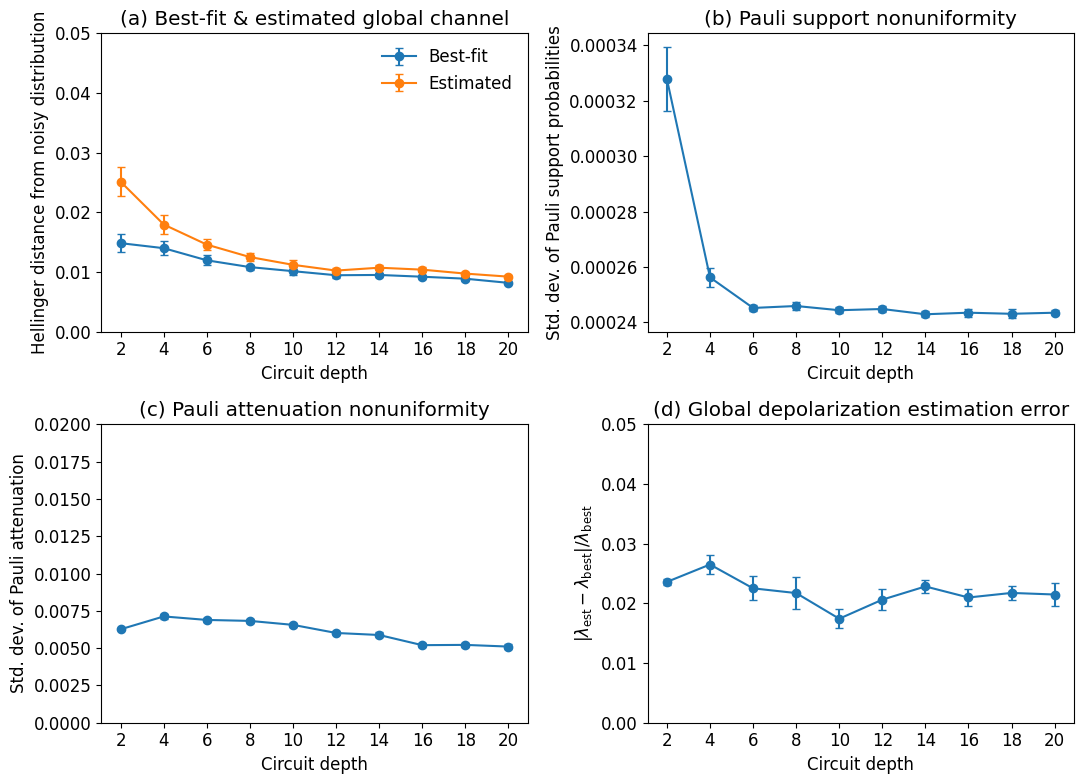

In [73]:
# ===================== Plotting ====================
from matplotlib.ticker import MaxNLocator
plt.rcParams.update({'font.size': 12}) 
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
depths = list(DEPTHS)


def plot_metric(ax, key, label=None, fmt="o-"):
    means, sems = [], []

    for d in depths:
        values = [
            r[key] for r in records if r["depth"] == d
        ]
        m, s = mean_sem(values)
        means.append(m)
        sems.append(s)

    ax.errorbar(
        depths, means, yerr=sems,
        fmt=fmt, capsize=3, label=label
    )
    ax.set_xlabel("Circuit depth")
    if label:
        ax.legend(frameon=False)

def plot_metrics(ax, keys, labels=None, fmt="o-"):
    for i, key in enumerate(keys):
        means, sems = [], []
        for d in depths:
            values = [
                r[key] for r in records if r["depth"] == d
            ]
            m, s = mean_sem(values)
            means.append(m)
            sems.append(s)

        ax.errorbar(
            depths, means, yerr=sems,
            fmt=fmt, capsize=3, label=(labels[i] if labels else None)
        )
        ax.set_xlabel("Circuit depth")
        if labels:
            ax.legend(frameon=False)


# (a) Top left
ax = axes[0, 0]
plot_metrics(ax, ["hellinger", "hellinger_theory"], ["Best-fit", "Estimated"])
ax.set_ylabel("Hellinger distance from noisy distribution")
ax.set_title("(a) Best-fit & estimated global channel")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_ylim(0,0.05)

# (b) Top right
ax = axes[0, 1]
plot_metric(ax, "pauli_std")
ax.set_ylabel("Std. dev. of Pauli support probabilities")
ax.set_title("(b) Pauli support nonuniformity")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

# (c) Bottom left
ax = axes[1, 0]
plot_metric(ax, "attenuation_std")
ax.set_ylabel("Std. dev. of Pauli attenuation")
ax.set_title("(c) Pauli attenuation nonuniformity")
ax.set_ylim(0, 0.02)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

# (d) Bottom right
ax = axes[1, 1]
plot_metric(
    ax, "normalized_theory_error"
)
ax.set_ylabel(r"$|\lambda_{\rm est}-\lambda_{\rm best}|/\lambda_{\rm best}$")
ax.set_title("(d) Global depolarization estimation error")
ax.set_ylim(0, 0.05)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

plt.tight_layout()
plt.show()
